# Credit Scoring — от данных к датасету

Полное исследование базы `academy_db` (таблицы `scoring_*`, срез **2025-05-31**).

**Артефакты:** `../REPORT.md`, `../RESEARCH_LOG.md`, `../DEFENSE_QA.md`, `../data/`

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

ROOT = Path('..').resolve()
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)

DB_USER = os.getenv('DB_USER', 'bkenesbaev')
DB_PASSWORD = os.getenv('DB_PASSWORD')
DSN = (
    f'postgresql://{DB_USER}:{DB_PASSWORD.replace("@", "%40")}'
    f'@thomas.proxy.rlwy.net:51432/academy_db?sslmode=require'
)
engine = create_engine(DSN)

def q(sql: str) -> pd.DataFrame:
    return pd.read_sql(text(sql), engine)

## Шаг 1. Постановка задачи

1. **Решение банка:** одобрение/отказ (`final_decision`); в перспективе — лимит и ставка.
2. **Событие:** 90+ DPD в первые **12 месяцев** после `issue_date`.
3. **Популяция:** заявки на потребительский кредит (18 000); PD-модель на approved (11 277).
4. **Данные на момент решения:** анкета, бюро (as-of `decision_date`), карты (6 мес. до решения), демография.
5. **Критерий успеха:** Gini/KS out-of-time + экономика (снижение bad rate при том же approval rate).

## Шаг 2. Разведка — все scoring_ таблицы

In [2]:
tables = q("""
SELECT tablename,
       pg_size_pretty(pg_total_relation_size('public.' || tablename)) AS size
FROM pg_tables
WHERE schemaname = 'public' AND tablename LIKE 'scoring\\_%'
ORDER BY tablename
""")
tables

,tablename,size
0,scoring_applications,2368 kB
1,scoring_applications_full,1176 kB
2,scoring_bureau_inquiries,3896 kB
3,scoring_bureau_loans,5072 kB
4,scoring_bureau_snapshots,7832 kB
5,scoring_card_disputes,336 kB
6,scoring_card_transactions,169 MB
7,scoring_cards,1312 kB
8,scoring_clients_old,552 kB
9,scoring_collection_actions,592 kB


In [3]:
decisions = q("""
SELECT final_decision, COUNT(*) cnt,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) pct
FROM scoring_applications
GROUP BY 1
""")
decisions

,final_decision,cnt,pct
0,approved,11277,62.65
1,rejected,6723,37.35


In [4]:
coverage = q("""
SELECT
  COUNT(DISTINCT a.client_id) AS app_clients,
  COUNT(DISTINCT a.client_id) FILTER (
    WHERE EXISTS (SELECT 1 FROM scoring_customers c WHERE c.customer_id = a.client_id)
  ) AS in_customers,
  COUNT(DISTINCT a.client_id) FILTER (
    WHERE EXISTS (SELECT 1 FROM scoring_card_transactions t WHERE t.client_id = a.client_id)
  ) AS with_card_txn
FROM scoring_applications a
""")
coverage

,app_clients,in_customers,with_card_txn
0,11328,5891,4164


### Таблица: источник → можно ли в фичи

| Источник | В фичи | Причина |
|----------|--------|--------|
| scoring_applications | ✅ | анкета до decision |
| scoring_contracts, payments | ❌ | post-issue / target |
| scoring_bureau_snapshots, inquiries | ✅ | as-of join |
| scoring_bureau_loans | ⚠️ | только open_date ≤ decision |
| scoring_cards, card_transactions, disputes | ✅ | окно до decision |
| scoring_applications_full | ❌ | leakage (dpd_max, collection) |
| scoring_payments_backup, clients_old, txn_sample, temp | ❌ | мусор/дубли |

## Шаг 3. Сбор таргета

In [5]:
# Пересобрать: uv run python ../scripts/run_analysis.py
target = pd.read_csv(DATA / 'target_dataset.csv', parse_dates=['decision_date', 'issue_date'])
target.head()

,application_id,client_id,decision_date,issue_date,contract_id,max_dpd,window_closed_12m,installments_in_window,target_90,target_60,target_30
0,9720,20882,2024-02-06,2024-02-07,6114,4.0,1,12,0.0,0.0,0.0
1,17928,5396,2024-11-20,2024-11-23,11233,4.0,0,6,NaN,NaN,NaN
2,7582,21095,2025-04-29,2025-05-04,4790,NaN,0,0,NaN,NaN,NaN
3,448,20603,2025-02-23,2025-02-26,273,0.0,0,3,NaN,NaN,NaN
4,6194,2961,2023-08-10,2023-08-13,3936,2.0,1,12,0.0,0.0,0.0


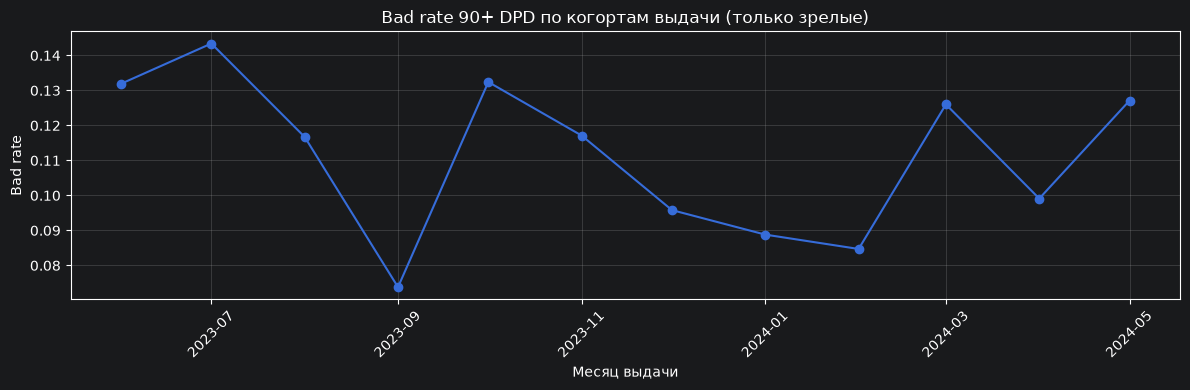

Labeled: 6561
Bad rate (labeled): 0.2047
Mature cohort bad rate range: 0.0738 - 0.1434


In [6]:
mature = pd.read_csv(DATA / 'bad_rate_by_month_mature_only.csv', parse_dates=['issue_month'])
mature_plot = mature.dropna(subset=['bad90_mature_only'])

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(mature_plot['issue_month'], mature_plot['bad90_mature_only'], marker='o')
ax.set_title('Bad rate 90+ DPD по когортам выдачи (только зрелые)')
ax.set_xlabel('Месяц выдачи')
ax.set_ylabel('Bad rate')
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUT / 'bad_rate_by_cohort.png', dpi=150)
plt.show()

print('Labeled:', target['target_90'].notna().sum())
print('Bad rate (labeled):', target['target_90'].mean().round(4))
print('Mature cohort bad rate range:', mature_plot['bad90_mature_only'].min(), '-', mature_plot['bad90_mature_only'].max())

**Определение target:**
- BAD: `max_dpd >= 90` в performance window 12 мес. от `issue_date`
- GOOD: окно закрыто и `max_dpd < 90`
- NULL: незрелый договор без 90+ DPD

## Шаг 4. Анализ проблемы

In [7]:
compare = q("""
WITH bureau_asof AS (
  SELECT DISTINCT ON (a.application_id)
    a.application_id, s.bureau_score
  FROM scoring_applications a
  LEFT JOIN scoring_bureau_snapshots s
    ON a.client_id = s.client_id AND s.snapshot_date <= a.decision_date
  ORDER BY a.application_id, s.snapshot_date DESC
)
SELECT a.final_decision,
  ROUND(AVG(a.requested_amount_uzs)) avg_amount,
  ROUND(AVG(a.declared_income_uzs)) avg_income,
  ROUND(AVG(b.bureau_score), 1) avg_bureau,
  COUNT(*) n
FROM scoring_applications a
LEFT JOIN bureau_asof b ON a.application_id = b.application_id
GROUP BY 1
""")
compare

,final_decision,avg_amount,avg_income,avg_bureau,n
0,approved,13718267.0,10192486.0,678.3,11277
1,rejected,10779161.0,6384541.0,540.8,6723


In [8]:
nulls = q("""
SELECT
  SUM(CASE WHEN employment_months IS NULL THEN 1 ELSE 0 END) AS emp_null,
  SUM(CASE WHEN declared_income_uzs IS NULL THEN 1 ELSE 0 END) AS income_null,
  COUNT(*) AS total
FROM scoring_applications
""")
nulls

,emp_null,income_null,total
0,1402,0,18000


## Шаг 5. Фичи (только до decision_date)

In [9]:
features = pd.read_csv(DATA / 'features_pre_decision.csv', parse_dates=['decision_date'])
dataset = pd.read_csv(DATA / 'modeling_dataset.csv', parse_dates=['decision_date', 'issue_date'])
print('Features:', features.shape)
print('Modeling dataset:', dataset.shape)
features.head()

Features: (11277, 23)
Modeling dataset: (11277, 31)


,application_id,client_id,decision_date,channel,purpose,requested_amount_uzs,term_months,declared_income_uzs,employment_months,gender,...,age_at_decision,bureau_score,existing_debt_uzs,active_loans_cnt,inq_cnt_6m,txn_approved_6m,txn_declined_6m,spend_6m,salary_in_6m,salary_to_declared_ratio
0,1,529,2024-08-27,mobile_app,education,20800000,18,6310000,204.0,F,...,50.0,644.0,16000000.0,3.0,1,37,3,49053990.0,39245539.0,6.2196
1,2,920,2023-10-19,branch,education,15300000,12,11120000,0.0,M,...,32.0,745.0,9000000.0,3.0,0,31,1,6734432.0,0.0,0.0000
2,3,7509,2023-07-01,branch,education,3900000,12,4140000,92.0,M,...,56.0,725.0,19000000.0,2.0,0,0,0,0.0,0.0,NaN
3,7,4522,2024-06-17,branch,repair,6100000,9,4500000,117.0,M,...,56.0,700.0,0.0,0.0,0,44,2,40072612.0,29895094.0,6.6434
4,10,7478,2025-02-28,agent,auto,2500000,24,14620000,177.0,F,...,47.0,698.0,7000000.0,3.0,0,40,0,68284869.0,59305537.0,4.0565


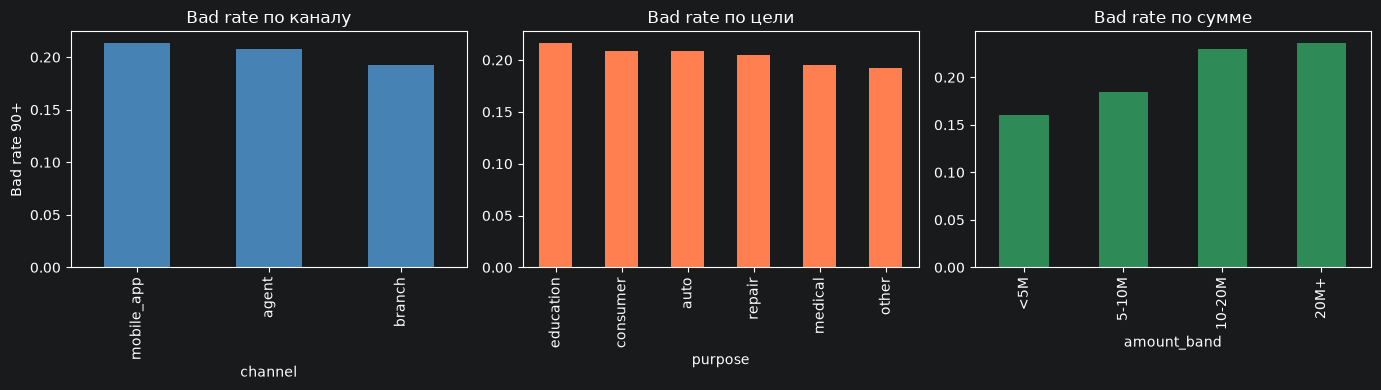

In [10]:
labeled = dataset[dataset['target_90'].notna()].copy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title in zip(
    axes,
    ['channel', 'purpose'],
    ['Bad rate по каналу', 'Bad rate по цели'],
):
    pass

by_ch = labeled.groupby('channel')['target_90'].mean().sort_values(ascending=False)
by_ch.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Bad rate по каналу')
axes[0].set_ylabel('Bad rate 90+')

by_p = labeled.groupby('purpose')['target_90'].mean().sort_values(ascending=False)
by_p.plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Bad rate по цели')

labeled['amount_band'] = pd.cut(
    labeled['requested_amount_uzs'],
    bins=[0, 5e6, 10e6, 20e6, 1e9],
    labels=['<5M', '5-10M', '10-20M', '20M+'],
)
labeled.groupby('amount_band', observed=True)['target_90'].mean().plot(
    kind='bar', ax=axes[2], color='seagreen'
)
axes[2].set_title('Bad rate по сумме')
plt.tight_layout()
plt.savefig(OUT / 'eda_bad_rates.png', dpi=150)
plt.show()

### Колонки-ловушки (leakage)

1. `dpd_max` в `scoring_applications_full` — прямая проекция target
2. `collection_calls_cnt` — следствие дефолта, не причина

## Шаг 6. Схема проверки (без обучения модели)

- **Split:** out-of-time — train issue ≤ 2024-02, valid 2024-03—05, test позже (mature only)
- **Метрики:** AUC/Gini (ранжирование), bad rate по децилям (калибровка), profit matrix
- **Стоимость ошибок** (ср. договор ~12M UZS):
  - Одобрили bad (FN): ~6M UZS потерь (LGD 50%)
  - Отклонили good (FP): ~1.8M UZS упущенной маржи
  - → консервативный cut-off оправдан

In [11]:
# Итоговый датасет для моделирования
out_cols = [
    'application_id', 'client_id', 'decision_date', 'target_90',
    'channel', 'purpose', 'requested_amount_uzs', 'term_months',
    'declared_income_uzs', 'employment_months', 'bureau_score',
    'existing_debt_uzs', 'inq_cnt_6m', 'salary_in_6m',
]
dataset[out_cols].head(10)

,application_id,client_id,decision_date,target_90,channel,purpose,requested_amount_uzs,term_months,declared_income_uzs,employment_months,bureau_score,existing_debt_uzs,inq_cnt_6m,salary_in_6m
0,9720,20882,2024-02-06,0.0,branch,medical,20400000,24,8610000,NaN,NaN,NaN,0,0.0
1,17928,5396,2024-11-20,NaN,branch,medical,7000000,18,5500000,95.0,788.0,1000000.0,0,0.0
2,7582,21095,2025-04-29,NaN,mobile_app,medical,18900000,12,10990000,NaN,476.0,0.0,1,0.0
3,448,20603,2025-02-23,NaN,branch,repair,4600000,12,2000000,228.0,773.0,0.0,0,0.0
4,6194,2961,2023-08-10,0.0,agent,other,21700000,24,24040000,122.0,747.0,3000000.0,0,125754553.0
5,9150,28700,2023-07-16,0.0,agent,repair,6300000,6,6090000,81.0,NaN,NaN,0,0.0
6,8664,1251,2024-07-12,NaN,branch,education,7000000,24,33070000,174.0,597.0,1000000.0,1,131705005.0
7,12139,30087,2024-06-01,NaN,agent,medical,3400000,12,2000000,103.0,NaN,NaN,1,0.0
8,6833,5286,2025-04-19,NaN,mobile_app,medical,10500000,18,9480000,8.0,590.0,5000000.0,1,0.0
9,3959,1282,2024-10-14,1.0,branch,other,6900000,24,5700000,220.0,576.0,12000000.0,1,0.0
